# Stock Classification with K-means and KNN

**FIM 590-003 — Project 02**  
**Group:** Joy Wu, Luolin Zhang, Jialin Zhang

This notebook reproduces the final nine-cluster model, the documented five-stock Morningstar comparison, a supplementary representative-stock check, KNN model selection, and ELF classification. The reusable implementation is in `src/stock_clustering.py`.

## 1. Setup and reproducible run

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "stock_clustering.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "stock_clustering.py").exists():
    raise FileNotFoundError("Run this notebook from inside the project directory.")
sys.path.insert(0, str(ROOT))

from src.stock_clustering import run_analysis

results = run_analysis(ROOT)
pd.Series(results["metrics"], name="Value").to_frame()

,Value
source_rows,1958.000000
modeled_rows,1161.000000
excluded_rows,797.000000
missing_peg_rows,797.000000
missing_peg_percent,0.407048
kmeans_clusters,9.000000
kmeans_inertia,376.278923
silhouette_score,0.342262
knn_best_k,15.000000
knn_cv_accuracy_mean,0.969010


The model uses only market capitalization and PEG ratio. Ticker is an identifier, not a feature. Rows with a missing or nonpositive feature are excluded; both retained features are transformed with `log10` before distance-based modeling.

## 2. Data audit and exploratory summary

In [2]:
pd.read_csv(ROOT / 'data/processed/data_quality_summary.csv')

,Metric,Value
0,Source rows,1958.000000
1,Unique tickers,1958.000000
2,Duplicate tickers,0.000000
3,Missing market capitalization,0.000000
4,Missing PEG ratio,797.000000
5,Nonpositive market capitalization,0.000000
6,Nonpositive PEG ratio,0.000000
7,Rows excluded from modeling,797.000000
8,Rows used for modeling,1161.000000
9,Rows retained (%),59.295199


In [3]:
raw = pd.read_csv(ROOT / "data/equity_data.csv")
raw[["Market_capital", "PEG ratio"]].describe(percentiles=[.25, .5, .75]).T

,count,mean,std,min,25%,50%,75%,max
Market_capital,1958.0,1.838728e+09,1.996305e+09,4.704041e+06,4.181133e+08,1.063996e+09,2.604428e+09,1.458955e+10
PEG ratio,1161.0,1.024929e+01,9.147316e+01,3.873000e-03,5.205860e-01,1.492798e+00,4.047014e+00,2.921253e+03


PEG is missing for 797 of 1,958 rows (40.70%), leaving 1,161 complete positive-feature observations. Log transformation reduces right-skew, and standardization prevents either logged feature from dominating Euclidean distance.

## 3. K-means model and nine project labels

In [4]:
cluster_summary = pd.read_csv(ROOT / "data/processed/cluster_summary.csv")
cluster_summary[[
    "Cluster_ID", "Raw_Cluster", "Style_Label", "Center_Market_capital_billions",
    "Center_PEG_ratio", "Stock_Count", "Stock_Share"
]].style.format({
    "Center_Market_capital_billions": "{:.3f}",
    "Center_PEG_ratio": "{:.3f}",
    "Stock_Share": "{:.1%}",
})

,Cluster_ID,Raw_Cluster,Style_Label,Center_Market_capital_billions,Center_PEG_ratio,Stock_Count,Stock_Share
0,1,3,Small Value,0.502,0.035,43,3.7%
1,2,6,Small Core,0.263,0.459,116,10.0%
2,3,5,Small Growth,0.325,4.123,124,10.7%
3,4,2,Mid Value,0.903,0.787,176,15.2%
4,5,8,Mid Core,1.402,3.323,169,14.6%
5,6,0,Mid Growth,0.706,41.530,71,6.1%
6,7,1,Large Value,2.716,0.141,136,11.7%
7,8,7,Large Core,4.361,1.399,221,19.0%
8,9,4,Large Growth,3.534,14.052,105,9.0%


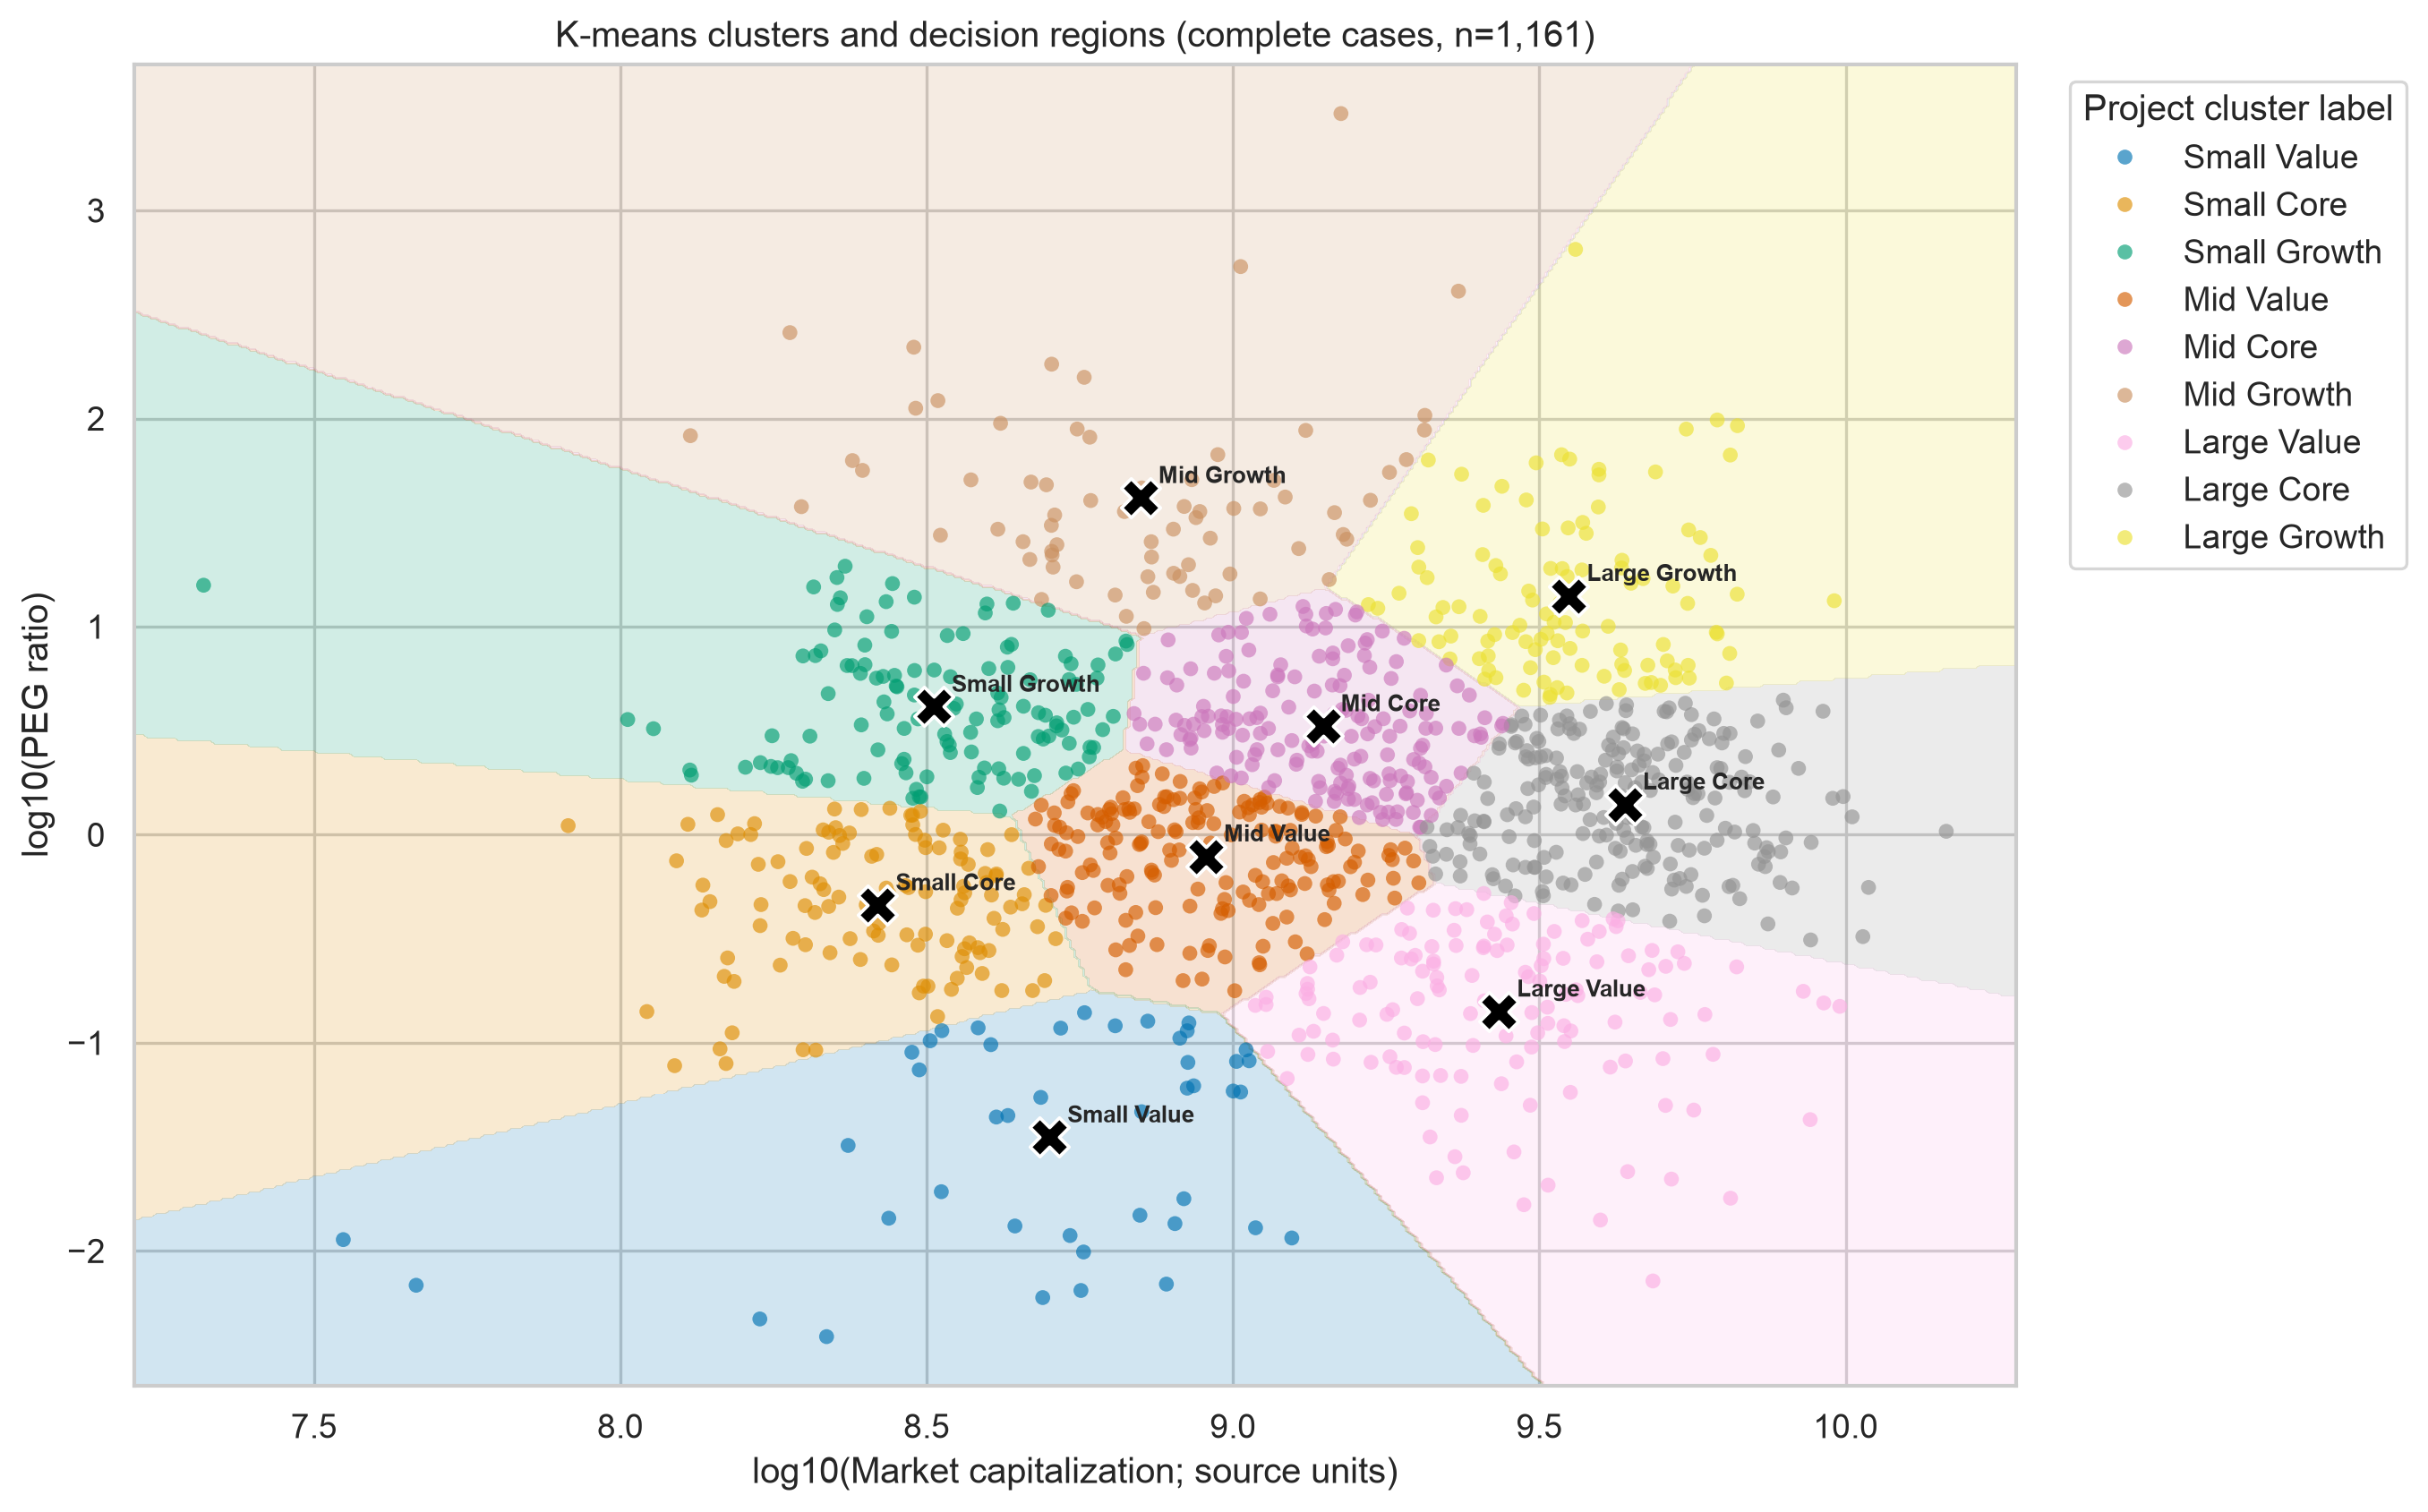

In [5]:
display(Image(filename=ROOT / 'outputs/figures/kmeans_clusters.png'))

K-means uses `n_clusters=9`, `n_init=50`, and `random_state=42`. Cluster centroids are ordered by market capitalization and split into three groups of three (Small, Mid, Large). Inside each group, PEG centroids are ordered low-to-high and named Value, Core, and Growth. These are relative project labels; the colored regions are K-means Voronoi regions in standardized log-feature space, not Morningstar boundaries.

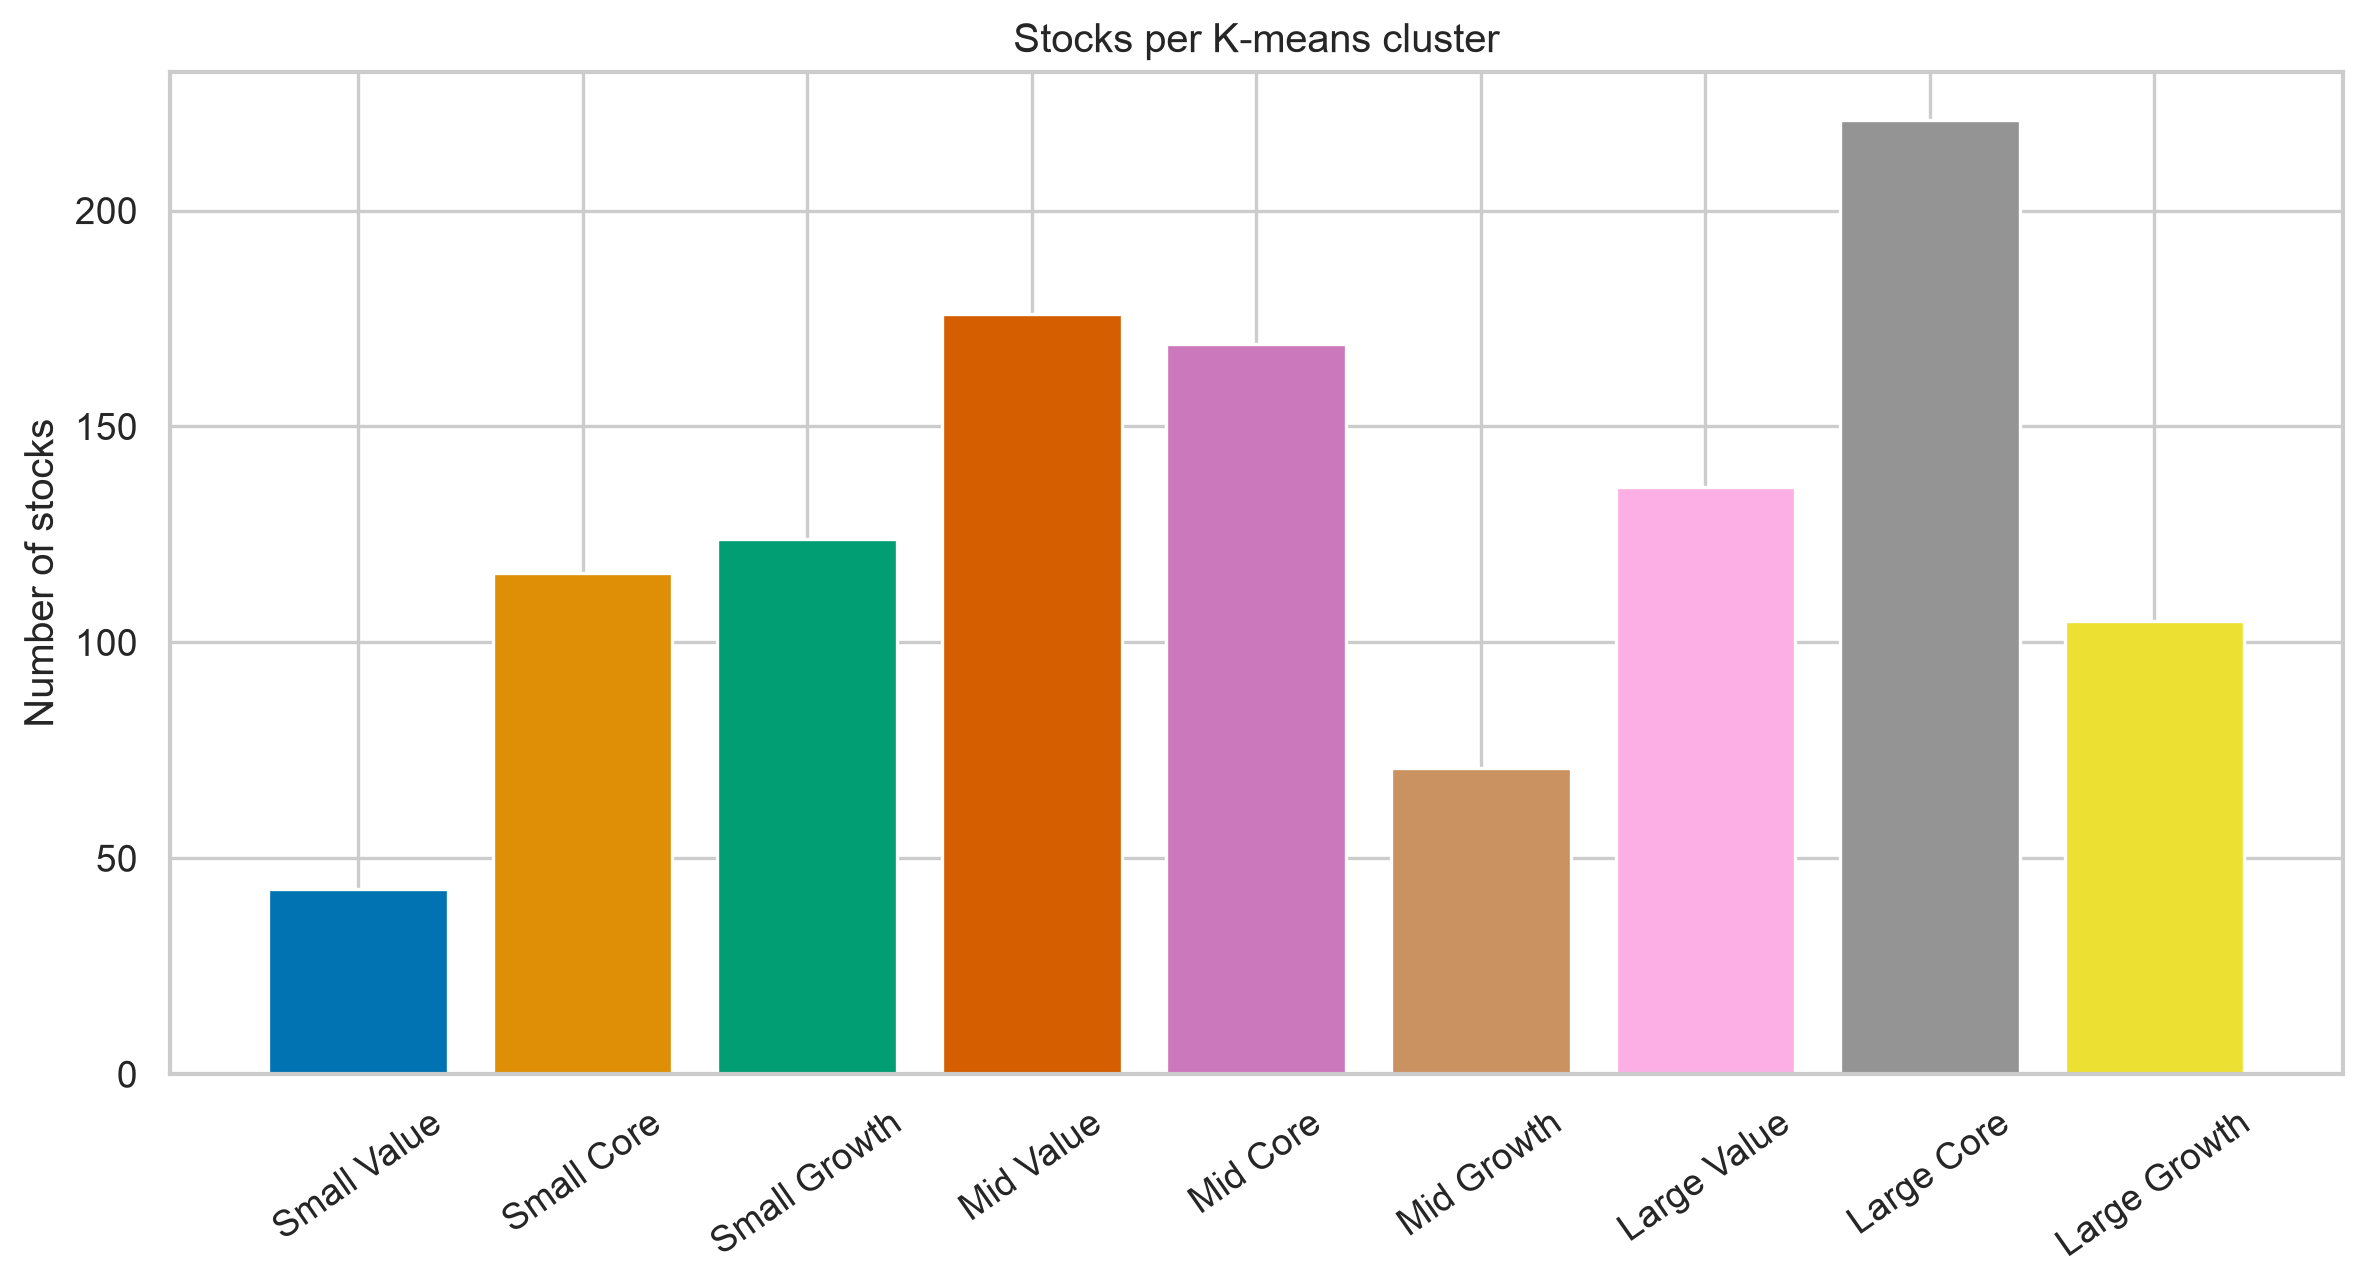

In [6]:
display(Image(filename=ROOT / 'outputs/figures/cluster_sizes.png'))

## 4. Five-stock comparison with Morningstar

In [7]:
favorite = pd.read_csv(ROOT / "data/processed/favorite_stock_comparison.csv")
favorite[[
    "Ticker", "KMeans_Style_Label", "Morningstar_Style_Label",
    "Size_Match", "Style_Match", "Overall_Match", "Morningstar_Access_Date"
]]

,Ticker,KMeans_Style_Label,Morningstar_Style_Label,Size_Match,Style_Match,Overall_Match,Morningstar_Access_Date
0,KODK,Small Value,Small Core,True,False,False,2026-11-22
1,PZZA,Small Growth,Small Value,True,False,False,2026-11-22
2,ROOT,Mid Value,Small Growth,False,False,False,2026-11-22
3,HOG,Large Core,Small Value,False,False,False,2026-11-22
4,RRR,Large Growth,Small Core,False,False,False,2026-11-22


KODK and PZZA agree with Morningstar on size only. ROOT, HOG, and RRR differ on both dimensions. Style agrees in 0 of 5 cases and no case is an exact match. Because these cases were deliberately selected for discussion, the counts are not a population accuracy estimate.

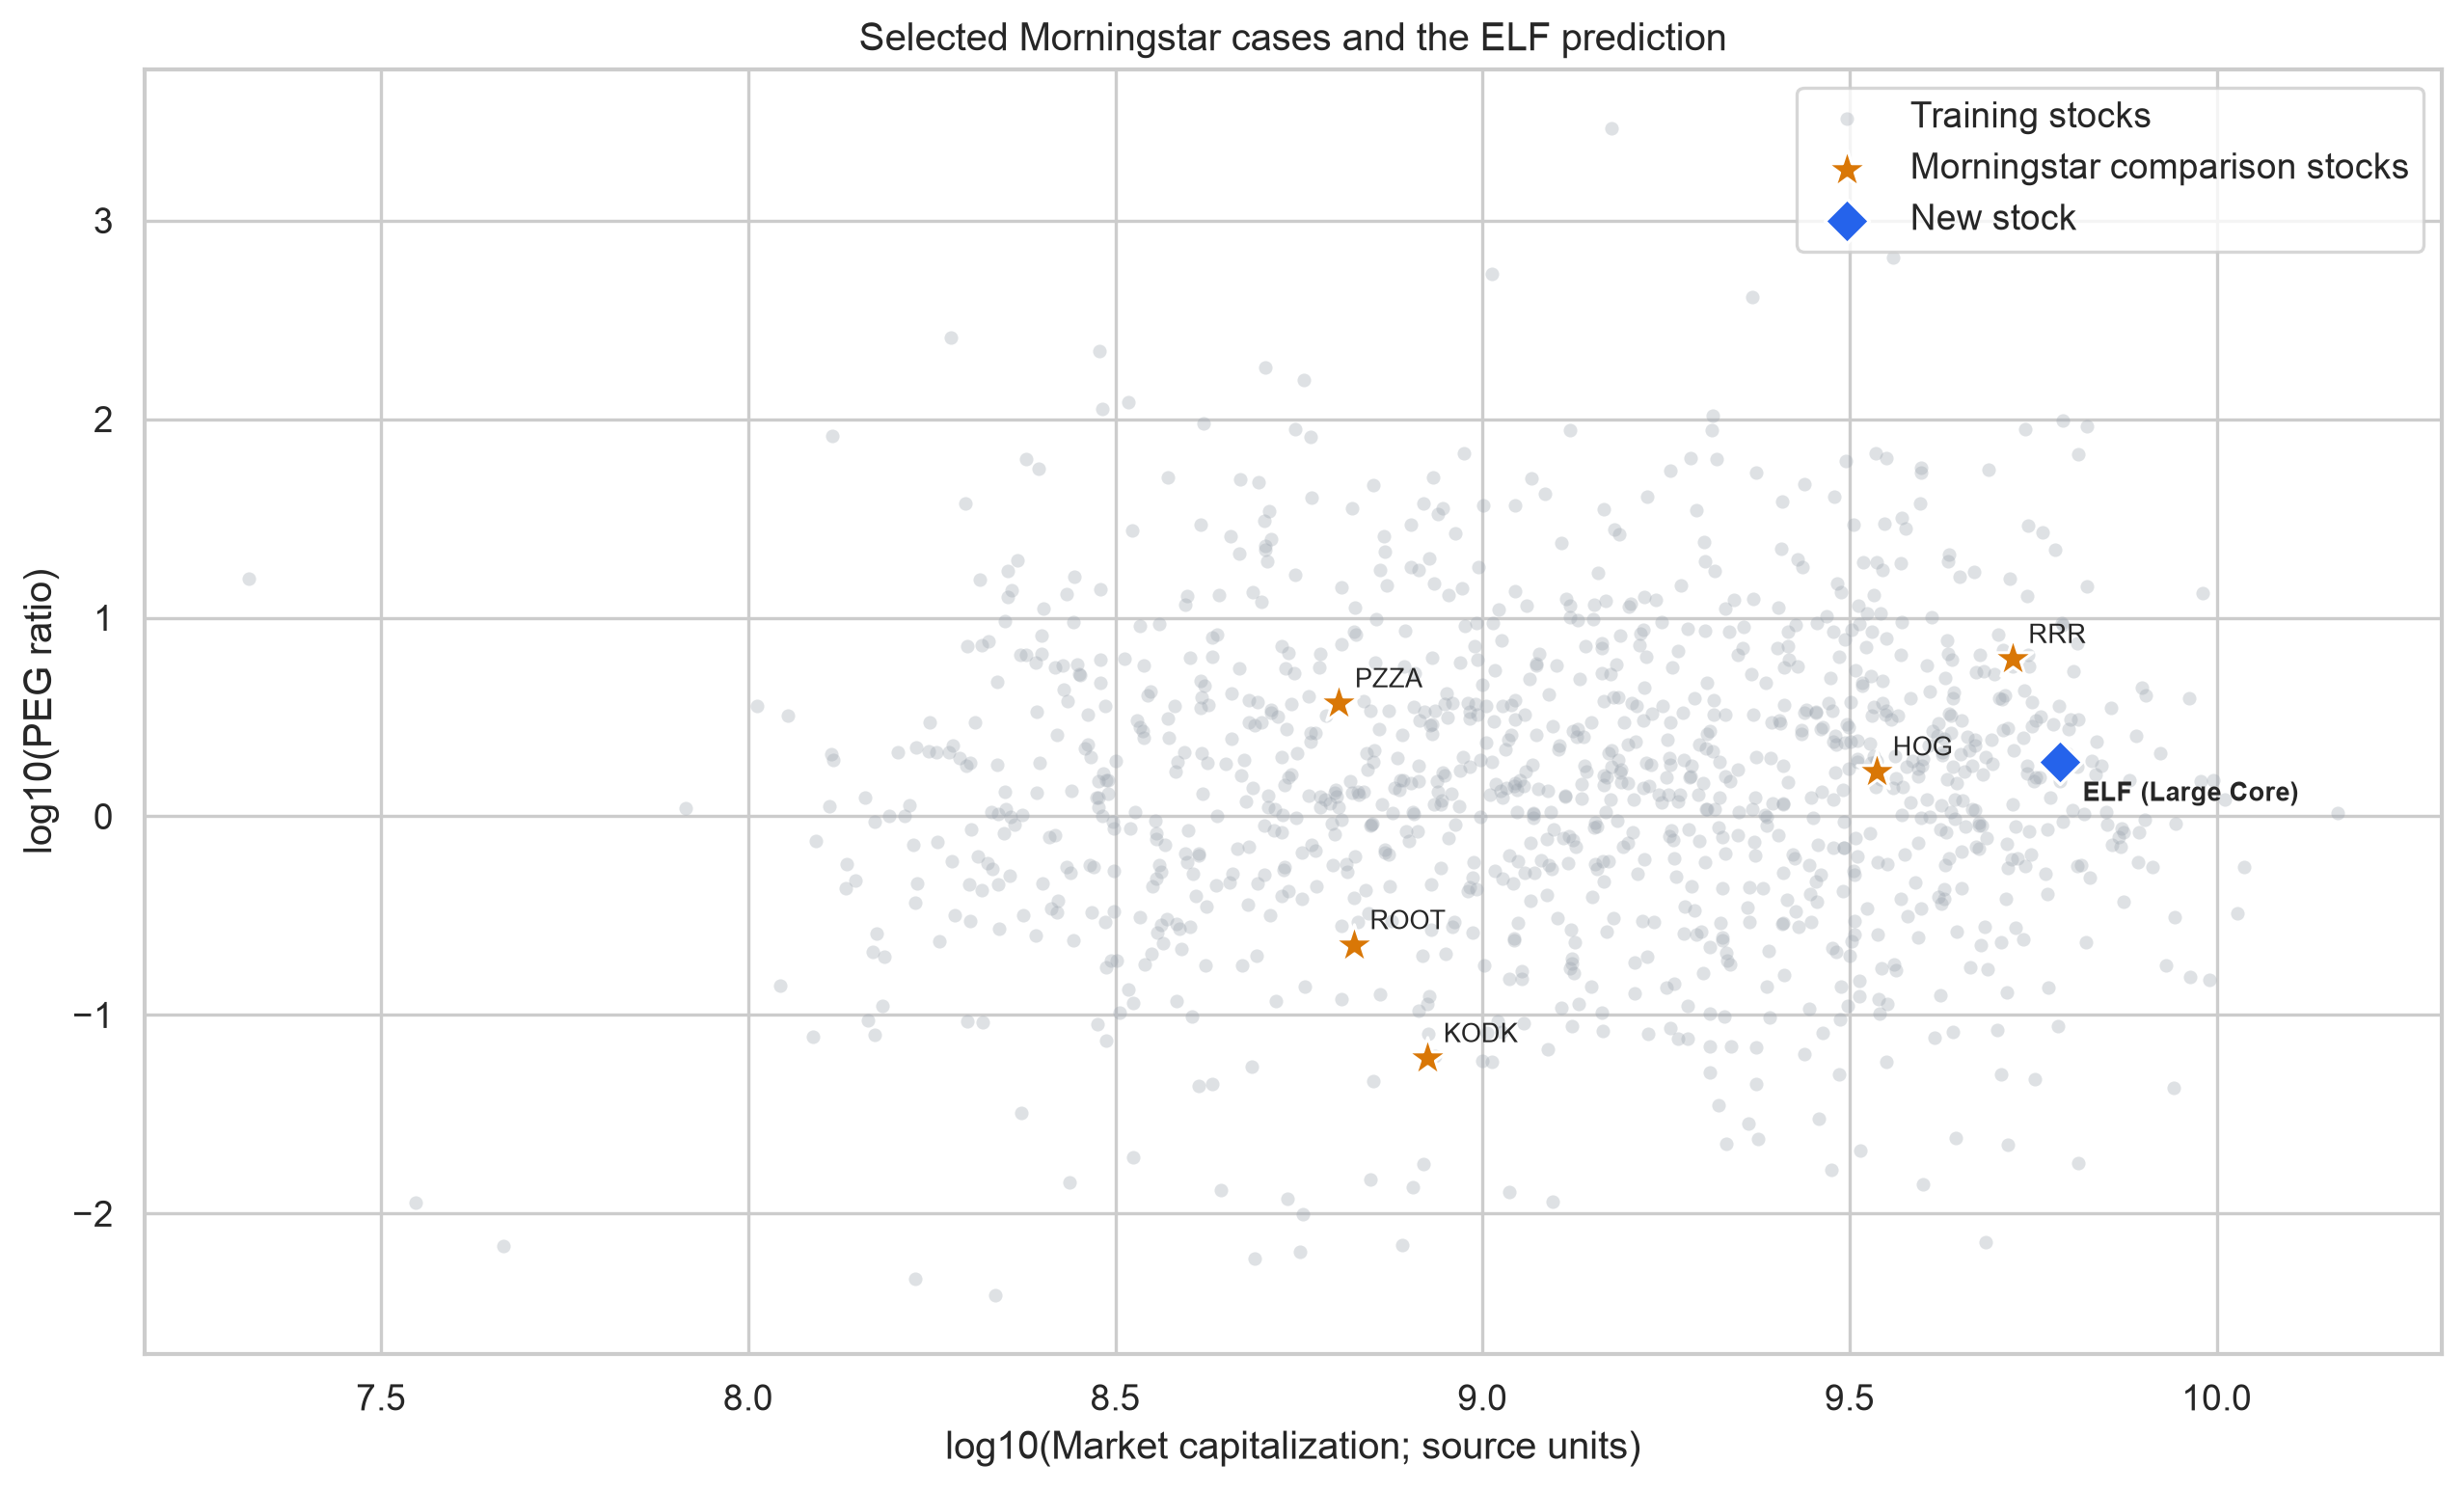

In [8]:
display(Image(filename=ROOT / 'outputs/figures/selected_stocks.png'))

## 5. Supplementary nine-cluster representative check

In [9]:
representatives = pd.read_csv(
    ROOT / "data/processed/representative_stock_comparison.csv",
    keep_default_na=False,
)
representatives[[
    "Ticker", "Model_Label", "Morningstar_Label", "Size_Match",
    "Style_Match", "Exact_Match", "Difference", "Evidence_Status"
]]

,Ticker,Model_Label,Morningstar_Label,Size_Match,Style_Match,Exact_Match,Difference,Evidence_Status
0,JAKK,Small Value,Small Value,True,True,True,None,Team-provided summary; original Morningstar UR...
1,ASLE,Small Core,Small Value,True,False,False,Style,Team-provided summary; original Morningstar UR...
2,ARL,Small Growth,Small Value,True,False,False,Style,Team-provided summary; original Morningstar UR...
3,WGO,Mid Value,Small Value,False,True,False,Size,Team-provided summary; original Morningstar UR...
4,IBTA,Mid Core,Small Value,False,False,False,Both,Team-provided summary; original Morningstar UR...
5,BFS,Mid Growth,Small Value,False,False,False,Both,Team-provided summary; original Morningstar UR...
6,ARDT,Large Value,Small Value,False,True,False,Size,Team-provided summary; original Morningstar UR...
7,HCC,Large Core,Small Value,False,False,False,Both,Team-provided summary; original Morningstar UR...
8,REZI,Large Growth,Small Value,False,False,False,Both,Team-provided summary; original Morningstar UR...


For each fitted cluster, the program selects the stock closest to its centroid in standardized log-feature space. The team-provided comparison reports three size matches, three style matches, and one exact match among the nine representatives. The uploaded summary does not include the original Morningstar URLs, access dates, or individual source screenshots, so this check remains separate from the five documented cases and is not treated as a population accuracy estimate.

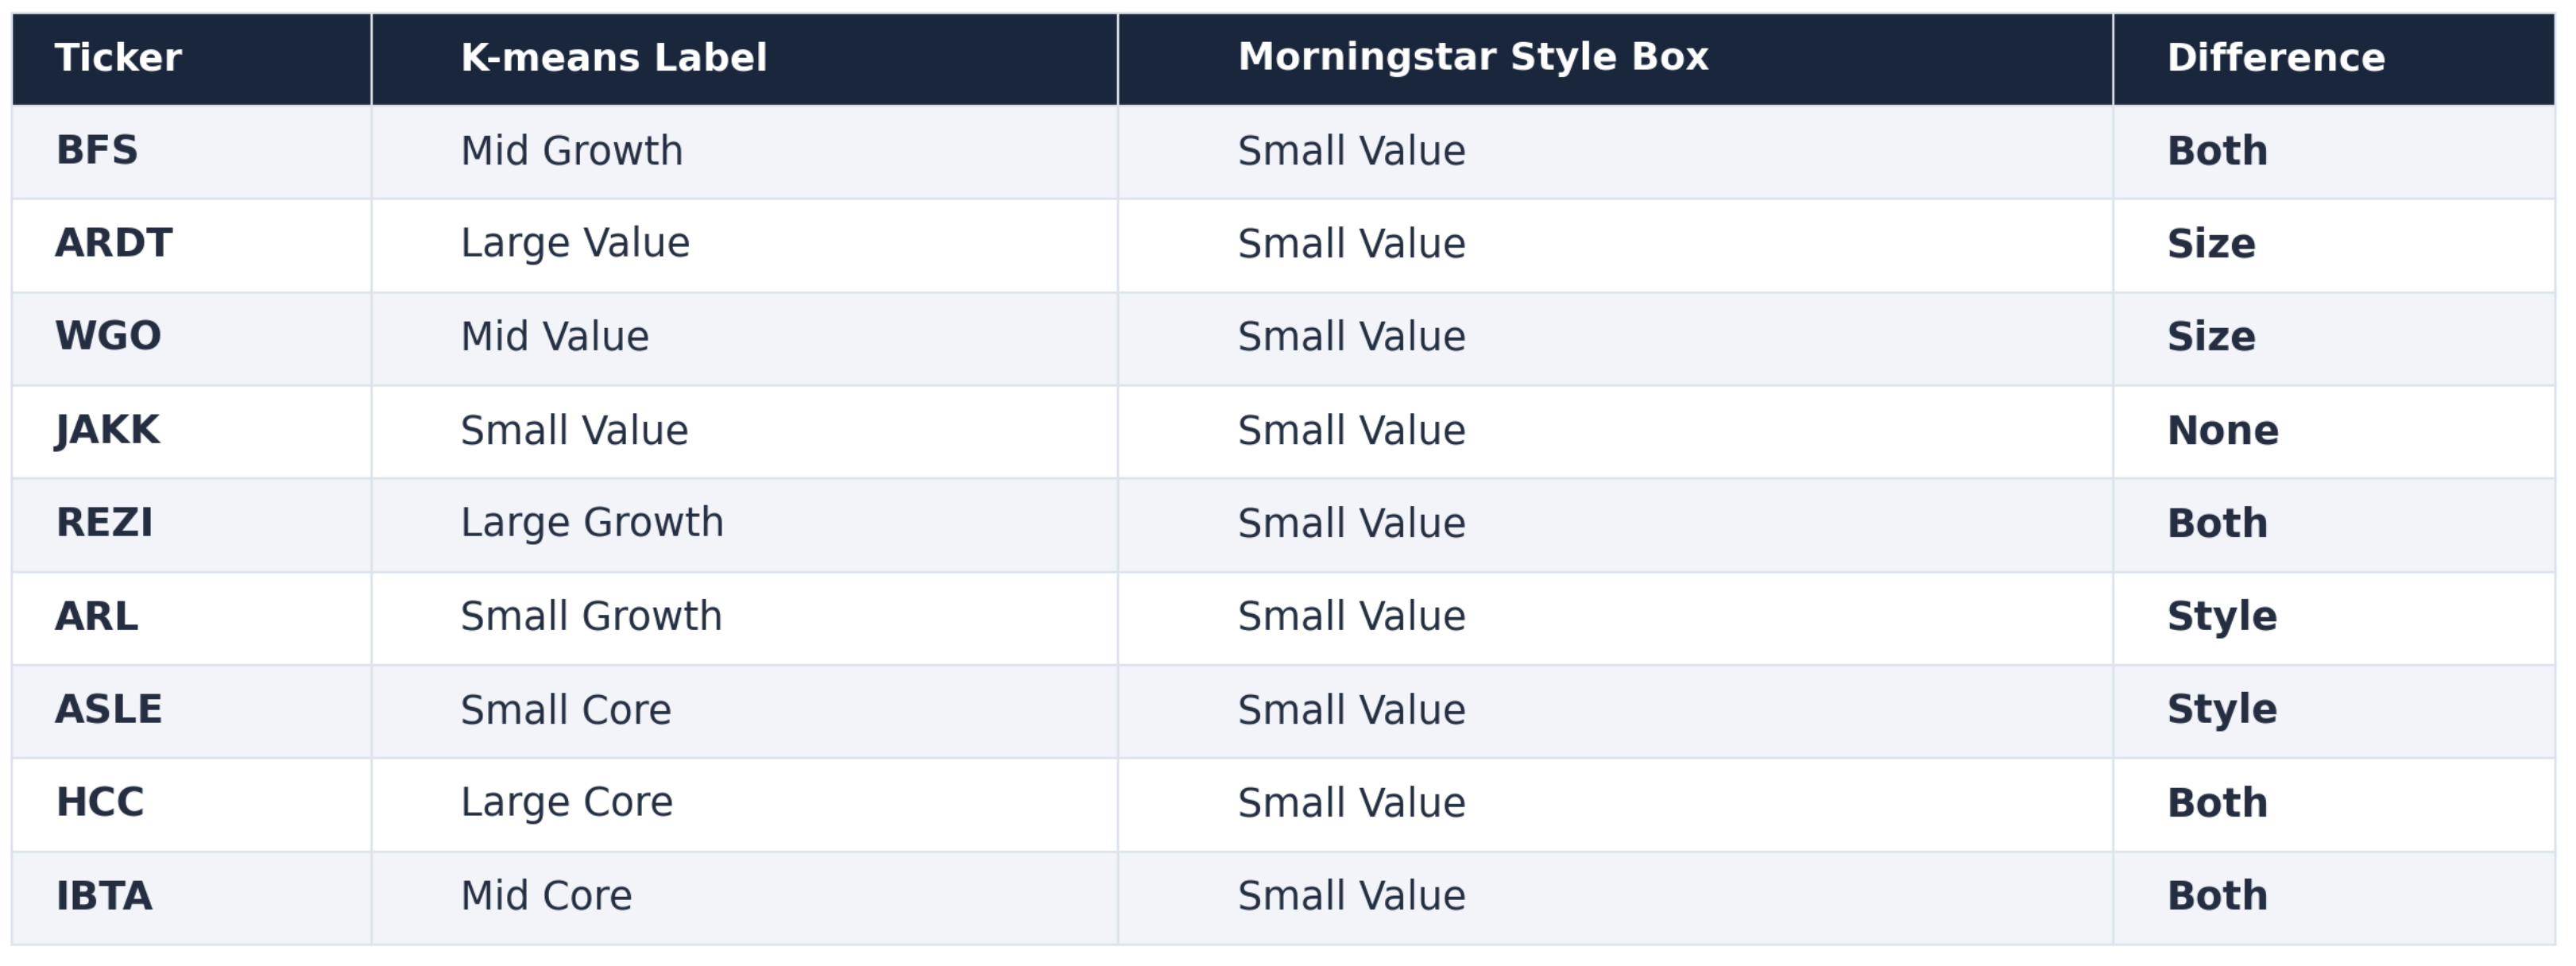

In [10]:
display(Image(filename=ROOT / 'K-Means Comparison.png'))

## 6. KNN model selection

In [11]:
cv = pd.read_csv(ROOT / "outputs/tables/knn_cv_results.csv")
cv.style.format({"Mean_CV_Accuracy": "{:.2%}", "SD_CV_Accuracy": "{:.2%}"})

,k,Mean_CV_Accuracy,SD_CV_Accuracy
0,3,95.78%,0.93%
1,5,95.69%,1.01%
2,7,96.21%,1.19%
3,9,96.21%,1.11%
4,11,96.56%,1.17%
5,15,96.90%,1.40%
6,21,96.73%,1.07%


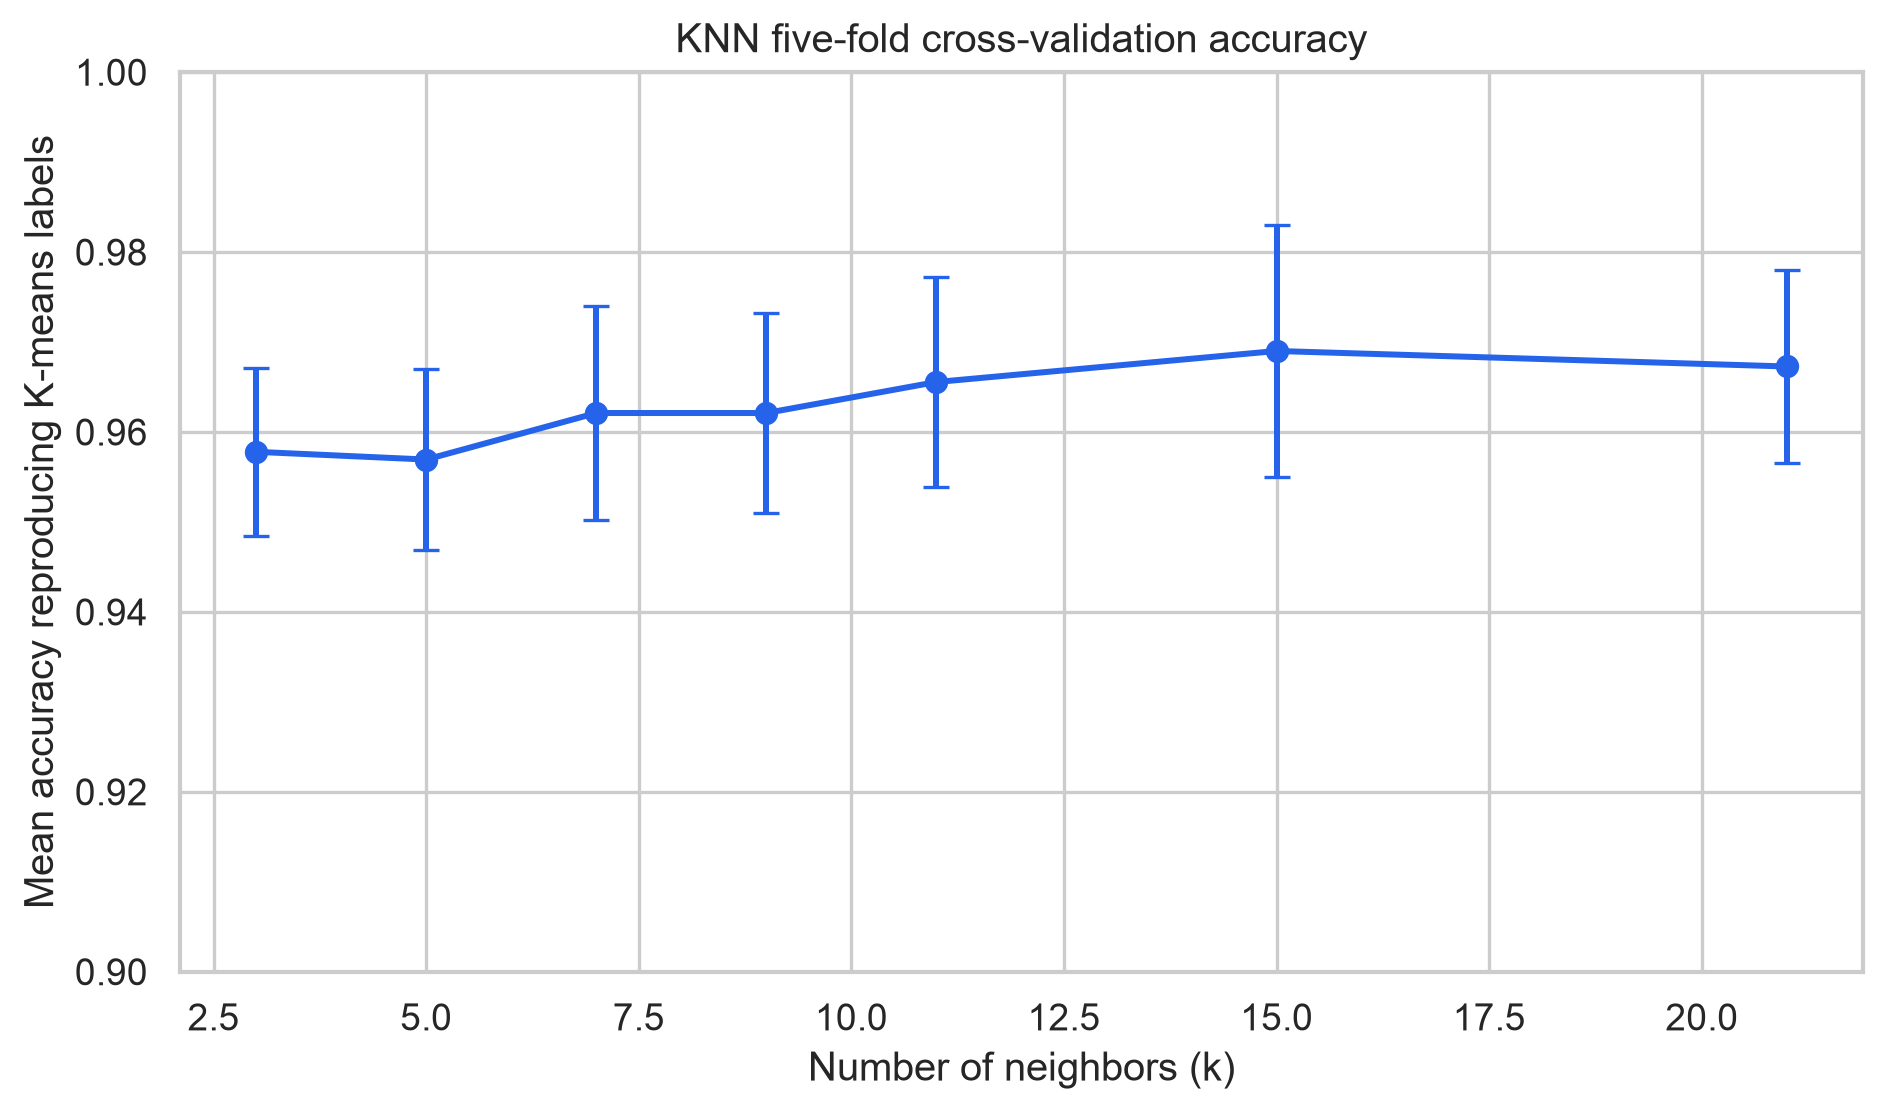

In [12]:
display(Image(filename=ROOT / 'outputs/figures/knn_cross_validation.png'))

A distance-weighted KNN classifier is trained on the two logged features to reproduce the nine K-means labels. Candidate values are evaluated with shuffled, stratified five-fold cross-validation. Scaling is inside the Pipeline, so it is fitted independently in every fold. The best candidate is `k=15`, with 96.90% mean agreement (1.40 percentage-point standard deviation). This does not measure Morningstar accuracy.

## 7. New-stock classification: ELF

In [13]:
prediction = pd.read_csv(ROOT / "data/processed/new_stock_prediction.csv")
prediction.T

,0
Ticker,ELF
Company_Name,"e.l.f. Beauty, Inc."
Market_capital,6120000000
PEG ratio,1.87
Data_As_Of_Date,2026-11-22
Source_URL,Bloomberg Terminal: ELF US Equity > DES > Profile
KNN_Size,Large
KNN_Style,Core
KNN_Style_Label,Large Core
KMeans_Size,Large


ELF uses Bloomberg market capitalization of USD 6.120 billion and `Est PEG` of 1.87, accessed November 22, 2026. It is not present in the training sample. KNN and the direct K-means consistency check both classify ELF as **Large Core**. Its values lie within the observed training ranges, although the original training PEG convention is not documented.

## 8. Limitations

- PEG is missing for 40.70% of the supplied rows, so complete-case selection may be biased.
- The training file omits constituent date, observation date, provider, market-capitalization unit/currency, and PEG convention.
- ELF uses Bloomberg Estimated PEG, which may not match the undocumented training PEG definition.
- A two-feature clustering model is much simpler than Morningstar's multi-factor Style Box methodology.
- The supplementary nine-stock comparison is based on a team-provided summary image without the original Morningstar links or access dates.
- Nine clusters are required by the assignment; the silhouette score of 0.3423 indicates overlapping rather than sharply separated groups.
- KNN validation measures reproduction of K-means-derived labels, not financial forecasting, Morningstar agreement, or investment performance.

## 9. Reproducibility

All generated CSVs and PNGs are created by `run_analysis(ROOT)`. The complete implementation—including validation, transformations, K-means, deterministic label mapping, KNN cross-validation, prediction, and plotting—is in `src/stock_clustering.py` and can be rerun from a clean environment using `requirements.txt`.